# 🌍 Phase 2: Storytelling with Data

Welcome to the **Exploration Phase**.
Here, we take our clean data and start asking questions. We want to find patterns and understand what makes an anime popular or highly rated.

**Key Goals:**
1.  **Understand Patterns**: Look at scores, popularity, and episode counts one by one.
2.  **Find Relationships**: Does being popular mean an anime is actually good?
3.  **Spot Unusual Cases**: Find the "Masterpieces" and the never-ending series that break the rules.
4.  **Controversy**: Find the shows that divide the community (Love/Hate).
5.  **Demographics**: See where the users are from.

## 0. Environment Setup
Configuring pandas display options and loading project modules.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option('display.max_columns', 200)

# 🔧 Dynamic Path Setup
current_dir = Path(os.getcwd())
project_root = current_dir.parent.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 📦 Import Project Modules
from solution.src.data import load_processed
from nb_02_exploration import (
    calculate_controversy_metric,
    setup_style,
    plot_distribution,
    plot_correlation_matrix,
    plot_categorical_comparison,
    generate_user_map,
    # New Advanced Modules
    analyze_moments, fit_distribution, analyze_cardinality,
    calculate_correlation, calculate_pps, plot_hexbin_density, plot_pps_heatmap,
    perform_pca, perform_clustering, plot_pca_3d,
    decompose_series, check_stationarity, resample_data,
    detect_isolation_forest, identify_outliers_zscore, identify_outliers_iqr
)

# Setup Visuals
setup_style()


c:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\.venv\Lib\site-packages\ppscore\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### 🧠 What do these groups tell us?
The table above shows the "centers" of our anime clusters. Think of these as the **archetypes** of anime:
-   **Row 0**: Might be "Average Anime" (Decent score, moderate popularity).
-   **Row 3**: Likely "Mega Hits" (High score, huge member count, lots of favorites).
-   **Row 4**: Could be "Niche/Cult Classics" or "Forgotten Shows" (Low popularity, varying scores).

By grouping them, we prove that anime isn't just one big blob; there are distinct tiers of success.


## 1. Load Data
We load the **optimized Parquet files** from `data/processed` using the shared project module.

In [2]:
df_details = load_processed("details")
df_stats = load_processed("stats")
df_profiles = load_processed("profiles")


### 1.1 Merge Data

Merge Anime relevant data into a unique DataFrame.


In [3]:
df_merged = df_details[
    ['anime_id', 'title', 'type', 'source', 'episodes', 'rating', 'score', 'scored_by', 
    'rank', 'popularity', 'members', 'favorites', 'year', 'season', 'start_date']
].merge(
    df_stats[['anime_id', 'watching', 'completed']], 
    on='anime_id',
    how='inner'
)
print(f"Merged Dataset Shape: {df_merged.shape}")


Merged Dataset Shape: (28939, 17)


## 2. Understanding the Shape of Data
Before connecting the dots, we need to understand each piece of data on its own.

### A. Beyond Averages
It's not enough to know the average score. We need to know:
1.  **The Middle**: Where is the center? (Mean/Median)
2.  **The Spread**: Is the data tightly packed or all over the place? (Variance)
3.  **The Tilt**: Is the data lopsided? Are there more low scores than high ones? (Skewness)
4.  **The Extremes**: Are there many extreme values ("Black Swans")? (Kurtosis)

We check these for `score`, `popularity`, and `members`.

In [4]:
moments_df = analyze_moments(df_merged, numeric_cols=['score', 'popularity', 'members', 'favorites', 'year', 'episodes'])
display(moments_df)


,Mean,Median,Variance,Std Dev,Skewness,Kurtosis
Column,,,,,,
score,6.390500,6.36,7.957438e-01,0.892045,-0.026912,0.120782
popularity,14493.569508,14489.00,7.007141e+07,8370.866690,0.000646,-1.200473
members,38774.744670,1080.00,2.802950e+10,167420.123048,9.846300,134.927584
favorites,431.087183,1.00,2.044711e+07,4521.848385,29.197111,1186.006989
year,2009.189015,2014.00,2.266420e+02,15.054633,-1.986976,5.682811
episodes,14.125986,2.00,2.224718e+03,47.166921,24.205347,1006.990085


### B. Checking Data Patterns
We want to see if our data follows standard shapes. This helps us predict behavior.
- **Normal (Bell Curve)**: Most things are average, with fewer extremes (e.g., scores often look like this).
- **Log-Normal**: Many small values, but a few huge ones (e.g., popularity - mostly obscure shows, a few massive hits).

We test mathematically to see which pattern fits best.

Fitting distributions for 'score':
Normal: p-value=0.0001, D-stat=0.0166
Log-Normal: p-value=0.0000, D-stat=0.0172


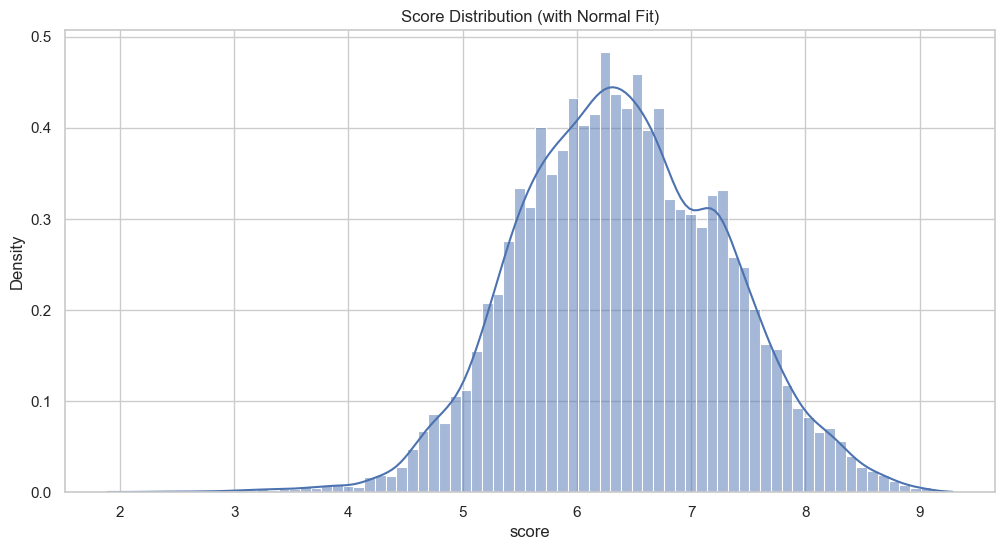

In [5]:
print("Fitting distributions for 'score':")
score_fits = fit_distribution(df_merged['score'])
for dist, res in score_fits.items():
    print(f"{dist}: p-value={res['p_value']:.4f}, D-stat={res.get('D_statistic', 'N/A'):.4f}")

plot_distribution(df_merged, 'score', title="Score Distribution (with Normal Fit)", kde=True)


### C. Counting Unique Values
We check how much variety exists in each column.
- **Low Variety**: Categories like "TV", "Movie", or "OVA".
- **High Variety**: Unique things like titles, IDs, or descriptions.

This tells us which data can be used for grouping (like "Type") and which is unique content.

In [6]:
cardinality_df = analyze_cardinality(df_details)
display(cardinality_df[cardinality_df['Classification'] != 'Unique Key'].sort_values('Percentage Unique'))


,Unique Values,Percentage Unique,Classification
Column,,,
explicit_genres,1,0.00%,Constant
status,3,0.01%,Low Cardinality (Categorical)
season,5,0.02%,Low Cardinality (Categorical)
rating,7,0.02%,Low Cardinality (Categorical)
type,10,0.03%,Low Cardinality (Categorical)
demographics,9,0.03%,Low Cardinality (Categorical)
source,17,0.06%,Low Cardinality (Categorical)
licensors,304,1.05%,Medium Cardinality
streaming,434,1.50%,Medium Cardinality


## 3. Finding Relationships

Now we see how different factors affect each other. Does one go up when the other goes down?

### A. Correlations

We look for connections:
*   **Simple connection (Pearson)**: If X doubles, does Y double?
*   **Rank connection (Spearman)**: If X acts like a top-tier show, does Y also act like one? (Good for popularity rankings).

**Reading the numbers:**
*   **+1.0**: They move perfectly together (Best friends).
*   **-1.0**: They move oppositely (e.g., Better Rank # means Higher Score).
*   **0.0**: No connection at all.


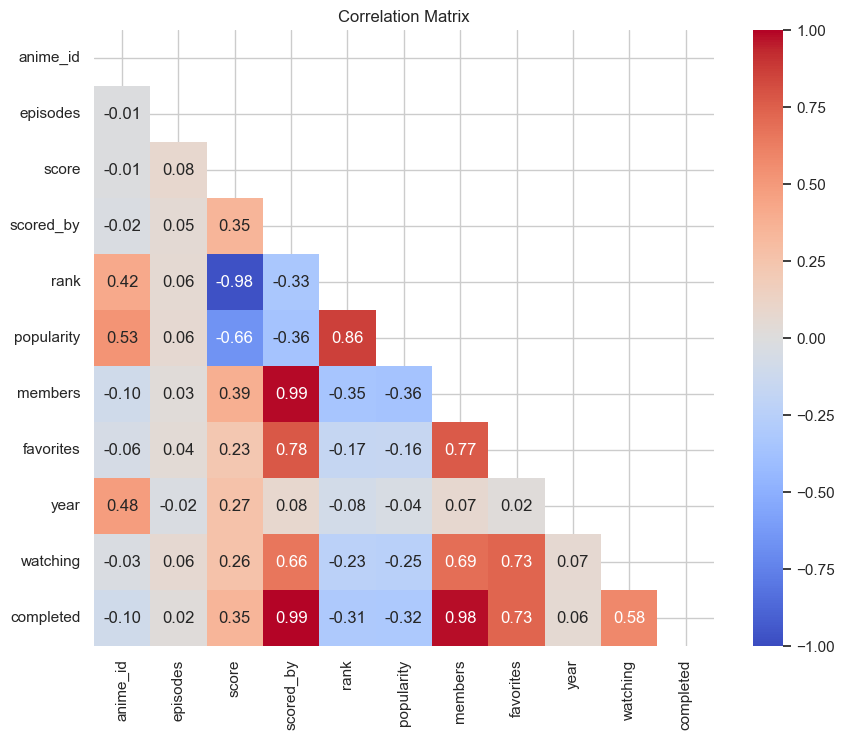

In [7]:
# Spearman Correlation (Monotonic)
corr_matrix = calculate_correlation(df_merged, method='spearman')
plot_correlation_matrix(df_merged)


### 📉 Correlation Structure (Spearman)
The heatmap above uses **Spearman Rank Correlation**.
-   **+1.0**: Strong positive match (As one goes up, the other goes up).
-   **-1.0**: Strong negative match (As one goes up, the other goes down).
-   **Why Spearman?** It captures "Monotonic" relationships (ranking), which is better for anime data (e.g. rank vs score) than standard linear correlation.


### B. Advanced Connections (PPS)

Sometimes the relationship isn't a straight line.
*   **PPS (Predictive Power Score)**: Can knowing X tell us Y, even if the relationship is weird or curved? This finds hidden patterns standard correlation misses.


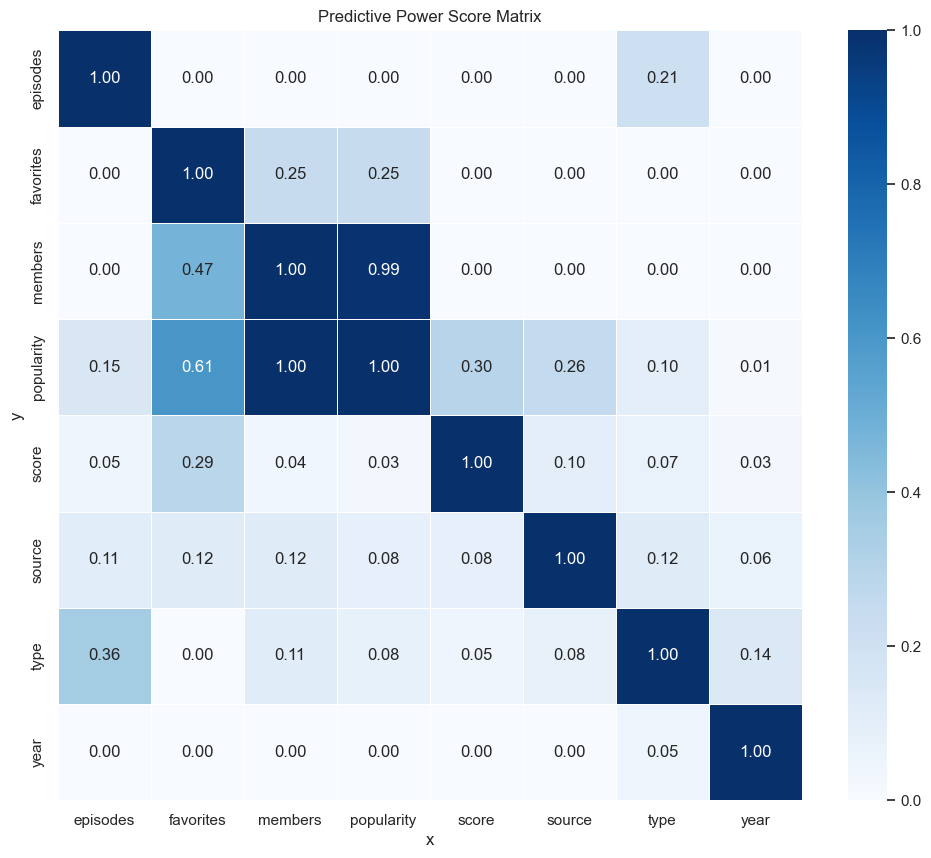

In [8]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    # Predictive Power Score (Non-Linear)
    # Note: Using sampling for speed if dataset is large
    pps_matrix = calculate_pps(df_merged[['score', 'popularity', 'members', 'favorites', 'year', 'episodes', 'type', 'source']])
    plot_pps_heatmap(pps_matrix)


### 🔮 Predictive Power Score (PPS)
**Why use PPS?**
Correlation only detects *linear* relationships (straight lines). PPS can find **non-linear** connections.
-   **Example**: `Time of Day` predicts `Temperature` well (high PPS), but they aren't linearly correlated (it goes up then down).
-   **Interpretation**: A high PPS (darker square) means column X can successfully predict column Y.


### C. Advanced Connection (Hexbins)

We use **Density Plots** (Hexbins) because we have too many dots for a normal scatter plot.

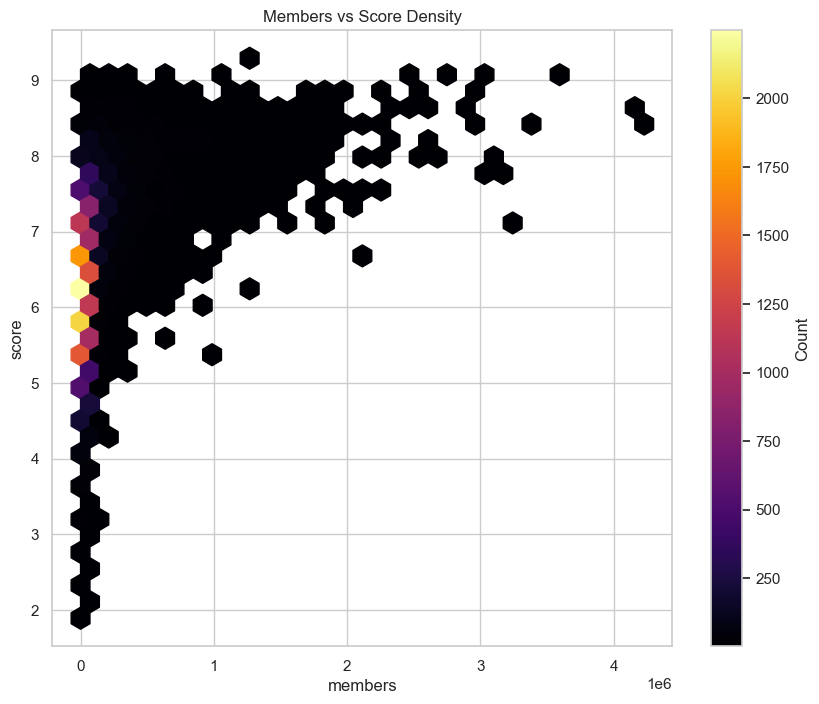

In [9]:
# Dense Data Visualization (Hexbin)
plot_hexbin_density(df_merged, 'members', 'score', title="Members vs Score Density")


### 🐝 Density Visualization (Hexbin)
When we have thousands of dots, scatter plots turn into a blob.
-   **Hexbin**: Groups dots into hexagons and colors them by density (count).
-   **Goal**: To see where the *majority* of anime lie in terms of Score vs Popularity (Members).
-   **Hotspots**: The bright areas show the most common combinations of score and popularity.


## 4. Simplifying Complex Data
Sometimes we have too much information to see the big picture. We need to simplify it.

### Finding Hidden Patterns
Imagine trying to draw a 3D object on a flat piece of paper. You lose some depth, but you keep the main shape. That's what we do here.

- **Squashing Data (PCA)**: We take many complicated numbers (Score, Episodes, Year, etc.) and squash them into a simple 2D or 3D map. This helps us see how anime relate to each other visually.
- **Grouping (Clustering)**: We let the computer find natural groups of anime (like "Mainstream Hits" vs. "Niche Classics") without us telling it what to look for.

### A. Making a Map (PCA)
**The Problem**: We can't see in 5 dimensions.
**The Solution**: We squish the data down to 2 or 3 dimensions so we can plot it.

*   **The Map**: We create a "map" of the anime world.
*   **The Meaning**: If two anime are close together on this map, they are similar in many ways (score, popularity, length, etc.) all at once.

In [10]:
# PCA
pca_df, pca_model = perform_pca(df_merged, numeric_cols=['score', 'popularity', 'members', 'favorites', 'year', 'episodes'])
display(pca_df.head())


Explained Variance Ratio: [0.36684006 0.18570443 0.16958195]
Total Variance Explained: 0.72


,PC1,PC2,PC3
0,-0.565439,-0.083692,-0.001329
1,-0.007325,0.841749,0.118651
2,0.465522,0.537338,-0.464040
3,0.805301,0.764590,-0.379551
4,0.171818,0.378006,-0.476592


### 📐 Dimensionality Reduction (PCA)
We have many numeric variables (Score, Members, Favorites, etc.). It's hard to visualize 5 dimensions at once!
-   **PCA**: Squashes these multiple dimensions into just 2 or 3 Principal Components (PC1, PC2, PC3).
-   **Goal**: Retain as much "information" (variance) as possible while making it simple enough to plot.
-   **Table**: Shows the "loadings" - which original columns contributed most to these new components.


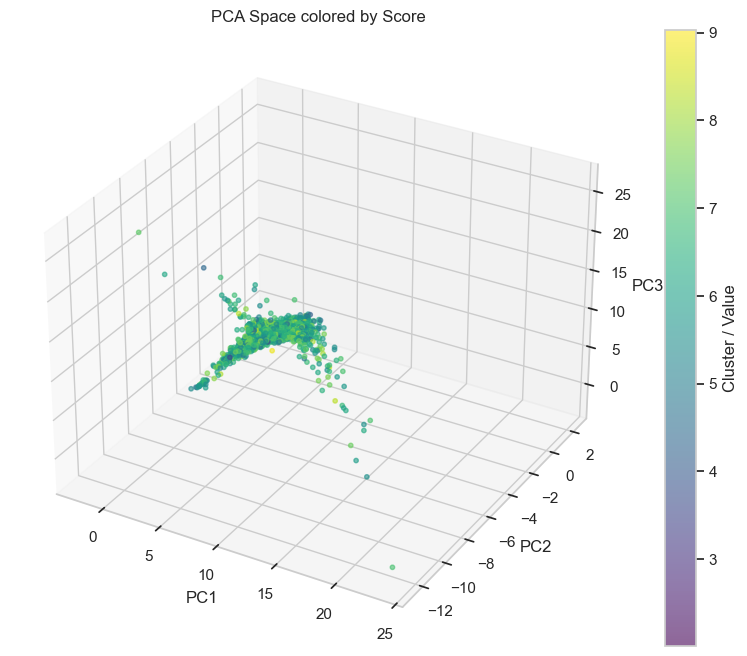

In [11]:
# 3D Visualization of PCA
# We can color by 'type' (TV, Movie, etc) to see if they separate naturally
plot_pca_3d(pca_df, color_col=df_merged['score'], title="PCA Space colored by Score")


### 🧊 3D Cluster Visualization
We project the anime into 3D space using our PCA components.
-   **Dots**: Each dot is an anime.
-   **Colors**: Represent the clusters we found earlier.
-   **Separation**: If the colors form distinct clouds, our clustering worked well! If they are mixed, the groups are fuzzy.


### B. Finding Natural Groups (Clustering)
We can ask the computer to sort anime into groups based on their similarities.
-   **K-Means**: This algorithm sorts anime into clusters.
-   **The Groups**: We might find a group of "Critically Acclaimed Dramas" or "Popular Action Shonens" without explicitly telling the computer these genres exist.

In [12]:
# Clustering (K-Means)
clustered_df, kmeans_model = perform_clustering(df_merged, numeric_cols=['score', 'popularity', 'members', 'favorites'])
print("Cluster Centers:")
display(pd.DataFrame(kmeans_model.cluster_centers_, columns=['score', 'popularity', 'members', 'favorites']))


Cluster Centers:


,score,popularity,members,favorites
0,6.936064,5426.701230,6.413746e+04,263.153485
1,7.480776,874.592606,3.564055e+05,3019.494014
2,6.379819,9020.248781,7.787116e+03,21.406527
3,7.995007,140.940493,1.392079e+06,27535.567489
4,6.149056,21171.922940,4.005336e+02,0.428173


### 🧠 What do these groups tell us?
The table above shows the "centers" of our anime clusters. Think of these as the **archetypes** of anime:
-   **Row 0**: Might be "Average Anime" (Decent score, moderate popularity).
-   **Row 3**: Likely "Mega Hits" (High score, huge member count, lots of favorites).
-   **Row 4**: Could be "Niche/Cult Classics" or "Forgotten Shows" (Low popularity, varying scores).

By grouping them, we prove that anime isn't just one big blob; there are distinct tiers of success.


## 5. Trends Over Time
Data changes over history. Anime from 1990 looks different from anime in 2020.

### A. Timeline
We look at how scores and popularity shift year by year.
-   **Resampling**: Grouping data by month or year to see the big trends instead of daily noise.
-   **Stability (Stationarity)**: Are things getting better, worse, or staying the same? We use a test (ADF) to check this mathematically.

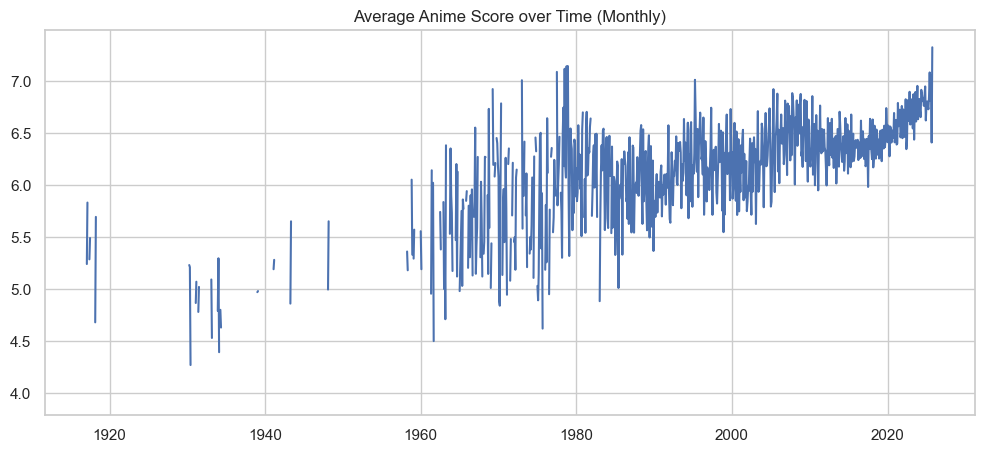

In [13]:
# Resample to Monthly Average Score
df_time = df_details.dropna(subset=['start_date']).copy()
monthly_scores = resample_data(df_time, 'start_date', rule='ME', columns=['score'])

plt.figure(figsize=(12, 5))
plt.plot(monthly_scores.index, monthly_scores['score'])
plt.title("Average Anime Score over Time (Monthly)")
plt.show()


### 📈 The History of Anime Scores
The chart above shows the average anime score over the years.
-   **If the line goes up**: Anime is generally getting better rated (or newer fans are more generous!).
-   **If it's flat**: Quality has been consistent for decades.
-   **Spikes**: Look for sharp ups and downs—these might be seasons with legendary shows or data glitches.


In [14]:
# Stationarity Test
check_stationarity(monthly_scores['score']);


Performing ADF Test on score...
ADF Statistic: -1.4335056206748318
p-value: 0.5661119221174651
Weak evidence against the null hypothesis -> Non-Stationary


### 📊 Stability Check (ADF Result)
We ran a statistical test (Augmented Dickey-Fuller) to see if the trends are stable.
-   **Non-Stationary**: Means the average score or variance **changes over time** (e.g., scores are drifting up). This confirms that "anime history" isn't a flat line; it evolves.
-   **Stationary**: Would mean scores basically stay in the same range forever. The result above suggests they **do** wander/change.


### ADF Results

**Non-Stationary**: It means that the "anime history" evolved during the years; it will give us a good amount of material to make a story on.

### Decomposition (Trend vs Seasonality)

We run a decomposition between trend and seasonality through a timeline divided in:
1.  **Trend**: The long-term direction (e.g., the slow steady rise of scores).
2.  **Seasonal**: Repeating patterns (e.g., do scores always dip in January?).
3.  **Resid (Residuals)**: The "noise" or random suprises left over after removing the trend and seasons. This is where the unexpected hits live.


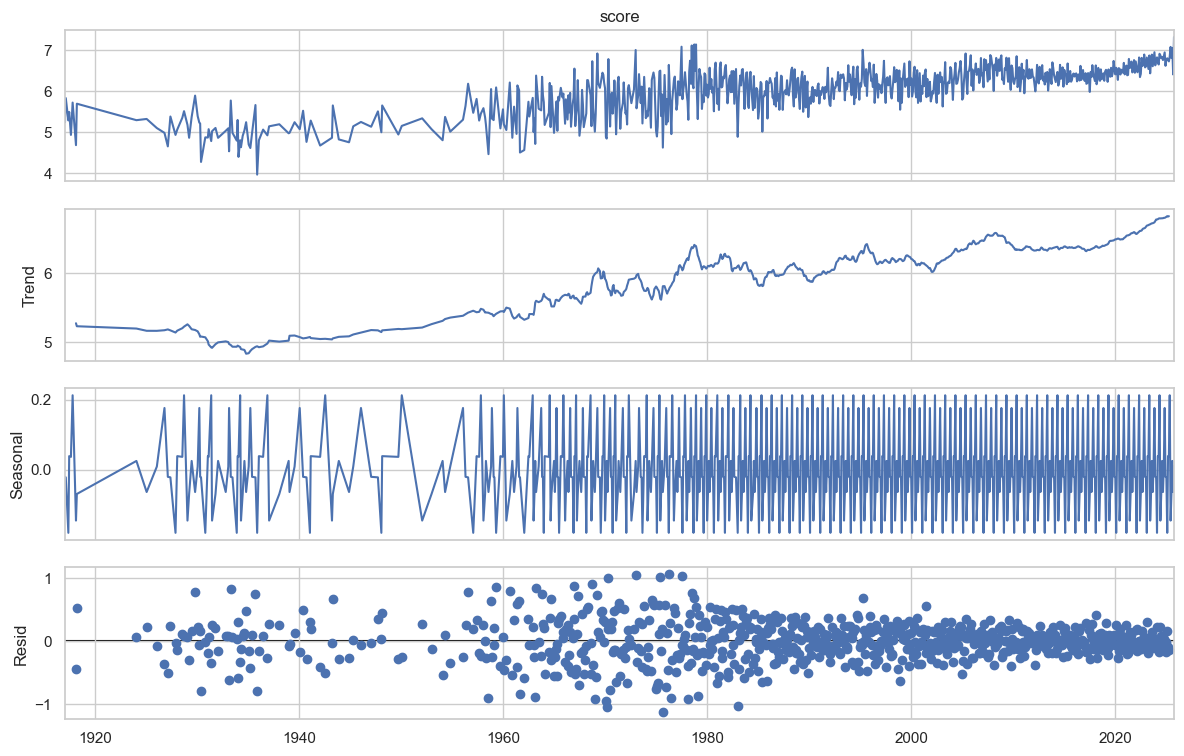

In [15]:
# Decomposition (Trend vs Seasonality)
# We use period=12 for yearly seasonality
decompose_series(monthly_scores['score'], period=12);


### 🔍 Breaking Down the Timeline

The most evident findings are talked by the **Seasonality** and the **Residuals** timelines: 

- Seasonality shows a clear pattern;
- Resid shows the dots were once sparse and then began converging at the end of the **'70**s.

They both give us a good material to work on to build the stories.


## 6. Anomaly Profiling (Outlier Analysis)
The outliers are often the most interesting part of the story (fraud, viral hits, errors).

### Global vs. Local Outliers
- **Global Outliers**: A value that is huge compared to everything (e.g., a masterpiece with millions of members).
- **Local Outliers**: Normal globally but weird for its context.

**Methods Used**:
- **Isolation Forest**: Detects anomalies in high-dimensional datasets by randomly splitting data; outliers are easier to isolate (require fewer splits).
- **Z-Scores**: Flagging items more than 3 Standard Deviations from the mean.

In [16]:
anomalies = detect_isolation_forest(df_merged, numeric_cols=['score', 'members', 'favorites'], contamination=0.005)
print("Top Anomalies:")
display(anomalies[['title', 'score', 'members', 'favorites', 'anomaly_score']].head(10))


Isolation Forest detected 145 anomalies in 28939 records.
Top Anomalies:


,title,score,members,favorites,anomaly_score
227,86,8.34,915727,25142,-0.001442
637,Akame ga Kill!,7.48,2215777,30329,-0.030390
955,Angel Beats!,8.05,2164124,49816,-0.032617
1074,Ano Hi Mita Hana no Namae wo Bokutachi wa Mada...,8.29,1679420,32971,-0.020442
1094,Another,7.46,1750083,18387,-0.017153
1102,Ansatsu Kyoushitsu,8.07,2156422,30979,-0.024296
1103,Ansatsu Kyoushitsu 2nd Season,8.47,1530002,17843,-0.012788
1138,Ao no Exorcist,7.47,2020793,17198,-0.022092
1695,Baccano!,8.35,945177,23620,-0.004129
1834,Bakemonogatari,8.32,1464558,50571,-0.028169


### 🌲 Isolation Forest Anomalies
What makes these shows "weird" (anomalous)?
-   **Mainstream Monsters**: Look at the `members` column. These shows have massive viewership (often 1M+).
-   **Engagement Kings**: High `favorites` counts show deep fan dedication.
-   **Verdict**: In this context, "Anomaly" doesn't mean *bad data*; it means **exceptional success**. These are the outliers of popularity that define the industry's upper limit.


In [17]:
z_outliers = identify_outliers_zscore(df_merged, 'members', threshold=4.0)
display(z_outliers[['title', 'members', 'zscore']].sort_values('zscore', ascending=False).head(10))


Z-Score Outliers for 'members': found 319 (Threshold: 4.0 sigma)


,title,members,zscore
21998,Shingeki no Kyojin,4230312,25.036475
4786,Death Note,4170767,24.680806
6589,Fullmetal Alchemist: Brotherhood,3576199,21.129392
17979,One Punch Man,3430848,20.261196
12294,Kimetsu no Yaiba,3323322,19.618932
23641,Sword Art Online,3232300,19.075248
2632,Boku no Hero Academia,3212739,18.958409
9667,Hunter x Hunter (2011),3080867,18.170724
16810,Naruto,3035328,17.898715
24907,Tokyo Ghoul,2984661,17.596076


### 🚨 Extreme Popularity Outliers (Z-Score)
The table above lists the **statistically massive** anime.
-   **Z-Score**: How many standard deviations away from the average. A Z-score of +25 is huge!
-   **The Findings**: These are not just "popular"; they are culturally ubiquitous (e.g. *Attack on Titan*, *Death Note*).
-   **Why it matters**: These shows likely skew any "average" calculations (like average members per genre). We might need to analyze them separately from the 'long tail' of standard anime.
